<a href="https://colab.research.google.com/github/painfulplatypusgh/finalproject/blob/main/CPE586_FinalProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (284807, 31) | Fraud rate: 0.173%
Train: 170883 (295 fraud)
Val:   56962 (99 fraud)
Test:  56962 (98 fraud)
Baseline Do-Nothing Loss: $10644.93

Training and calibrating: Logistic Regression (Class-Weighted)...


,Model,AUPRC,Brier (Raw -> Cal),Loss @ 0.50 ($),Loss @ Global ($),Loss @ Bayes t_i ($)
0,Logistic Regression (Class-Weighted),0.7347,0.02266 -> 0.00058 (Isotonic),2440.71,2413.72,2226.39


Training and calibrating: Logistic Regression (SMOTE)...


,Model,AUPRC,Brier (Raw -> Cal),Loss @ 0.50 ($),Loss @ Global ($),Loss @ Bayes t_i ($)
0,Logistic Regression (Class-Weighted),0.7347,0.02266 -> 0.00058 (Isotonic),2440.71,2413.72,2226.39
1,Logistic Regression (SMOTE),0.7142,0.00301 -> 0.00068 (Isotonic),2447.92,2427.72,2347.40


Training and calibrating: RandomForest (Weighted)...


,Model,AUPRC,Brier (Raw -> Cal),Loss @ 0.50 ($),Loss @ Global ($),Loss @ Bayes t_i ($)
0,Logistic Regression (Class-Weighted),0.7347,0.02266 -> 0.00058 (Isotonic),2440.71,2413.72,2226.39
1,Logistic Regression (SMOTE),0.7142,0.00301 -> 0.00068 (Isotonic),2447.92,2427.72,2347.40
2,RandomForest (Weighted),0.7919,0.00083 -> 0.00049 (Isotonic),2507.77,2507.77,2462.88


... (2 outputs left out)

Training and calibrating: MLP Neural Net (Weighted)...


,Model,AUPRC,Brier (Raw -> Cal),Loss @ 0.50 ($),Loss @ Global ($),Loss @ Bayes t_i ($)
0,Logistic Regression (Class-Weighted),0.7347,0.02266 -> 0.00058 (Isotonic),2440.71,2413.72,2226.39
1,Logistic Regression (SMOTE),0.7142,0.00301 -> 0.00068 (Isotonic),2447.92,2427.72,2347.40
2,RandomForest (Weighted),0.7919,0.00083 -> 0.00049 (Isotonic),2507.77,2507.77,2462.88
3,RandomForest (SMOTE),0.8463,0.00090 -> 0.00042 (Isotonic),2483.77,2483.77,2632.88
4,MLP Neural Net (Weighted),0.7112,0.00100 -> 0.00059 (Isotonic),4130.40,4130.40,2306.49


Training and calibrating: MLP Neural Net (SMOTE)...


,Model,AUPRC,Brier (Raw -> Cal),Loss @ 0.50 ($),Loss @ Global ($),Loss @ Bayes t_i ($)
0,Logistic Regression (Class-Weighted),0.7347,0.02266 -> 0.00058 (Isotonic),2440.71,2413.72,2226.39
1,Logistic Regression (SMOTE),0.7142,0.00301 -> 0.00068 (Isotonic),2447.92,2427.72,2347.40
2,RandomForest (Weighted),0.7919,0.00083 -> 0.00049 (Isotonic),2507.77,2507.77,2462.88
3,RandomForest (SMOTE),0.8463,0.00090 -> 0.00042 (Isotonic),2483.77,2483.77,2632.88
4,MLP Neural Net (Weighted),0.7112,0.00100 -> 0.00059 (Isotonic),4130.40,4130.40,2306.49
5,MLP Neural Net (SMOTE),0.5796,0.00602 -> 0.00077 (Isotonic),5394.19,4596.67,4443.44


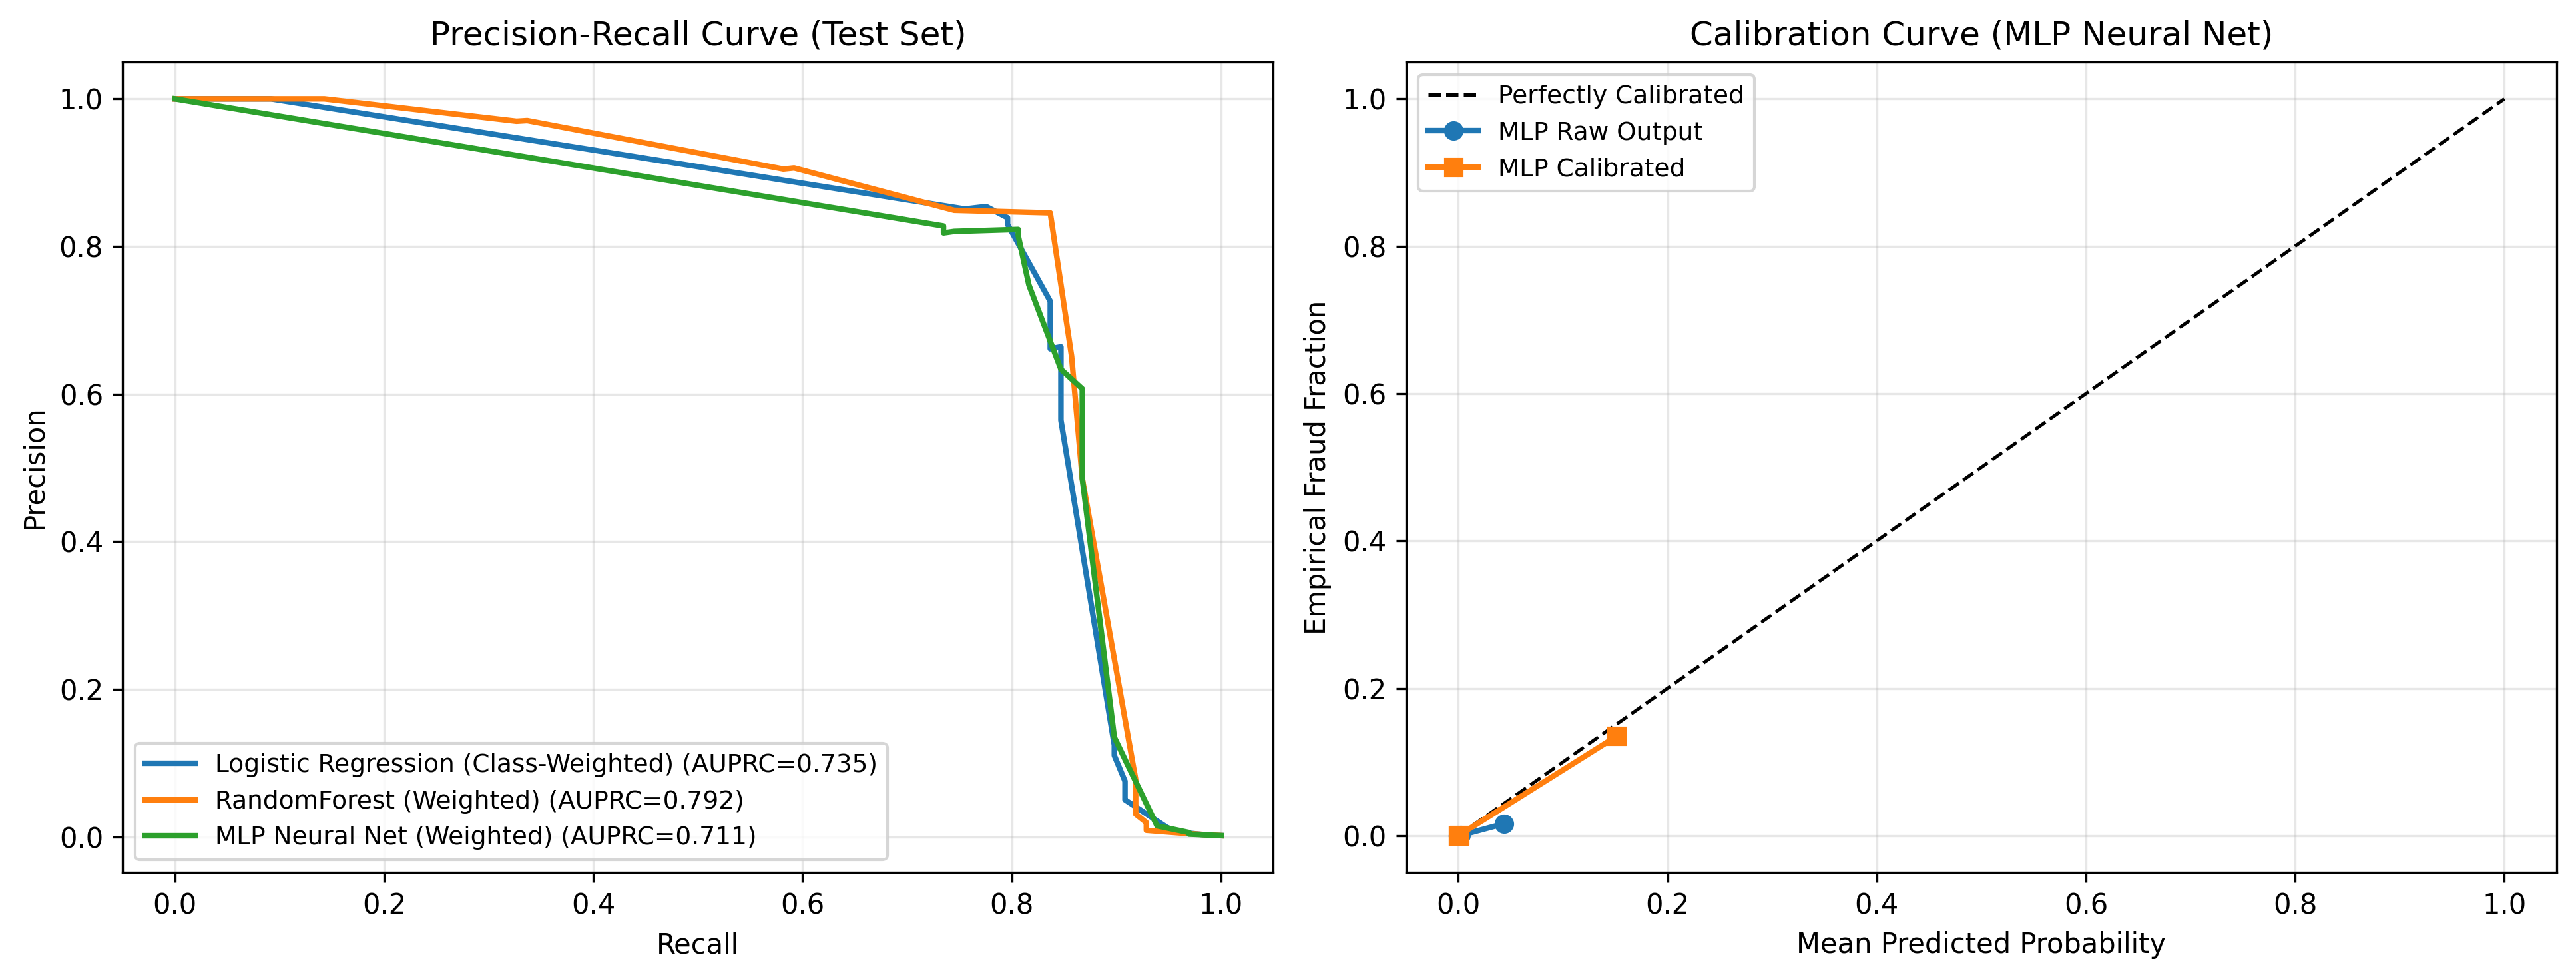

In [ ]:
!pip install -q imbalanced-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.preprocessing import RobustScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

from imblearn.over_sampling import SMOTE

# Ignore warnings
warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Load dataset (update path if stored in Google Drive)
df = pd.read_csv("creditcard.csv")
print(f"Dataset shape: {df.shape} | Fraud rate: {df['Class'].mean()*100:.3f}%")

#Cyclical time
df["Hour_sin"] = np.sin(2 * np.pi * (df["Time"] % 86400) / 86400)
df["Hour_cos"] = np.cos(2 * np.pi * (df["Time"] % 86400) / 86400)

#Separating features, labels, and raw dollar amounts
feature_cols = [f"V{i}" for i in range(1, 29)] + ["Amount", "Hour_sin", "Hour_cos"]
X = df[feature_cols].copy()
y = df["Class"].values
raw_amount = df["Amount"].values  #Unscaled dollar values for Bayes Risk cost rule

#60/20/20 data split
X_temp, X_test, y_temp, y_test, amt_temp, amt_test = train_test_split(
    X, y, raw_amount, test_size=0.2, stratify=y, random_state=SEED
)

X_train, X_val, y_train, y_val, amt_train, amt_val = train_test_split(
    X_temp, y_temp, amt_temp, test_size=0.25, stratify=y_temp, random_state=SEED
)

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {len(y_train)} ({y_train.sum()} fraud)")
print(f"Val:   {len(y_val)} ({y_val.sum()} fraud)")
print(f"Test:  {len(y_test)} ({y_test.sum()} fraud)")


#Create our neural network
tf.random.set_seed(SEED)

class TabularMLP(BaseEstimator, ClassifierMixin):
  #2-layer Multi-Layer Perceptron with ReLU, BatchNorm, and Dropout
  _estimator_type = "classifier"
  def __sklearn_tags__(self):
    tags = super().__sklearn_tags__()
    tags.estimator_type = "classifier"
    return tags

  def __init__(self, pos_weight=1.0, epochs=25, batch_size=512, lr=0.001):
    self.pos_weight = pos_weight
    self.epochs = epochs
    self.batch_size = batch_size
    self.lr = lr

  def _build_model(self, n_features):
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=self.lr),
        loss="binary_crossentropy"
    )
    return model

  def fit(self, X, y):
    self.classes_ = np.unique(y)
    self.model_ = self._build_model(X.shape[1])
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    )
    class_weight = {0: 1.0, 1: self.pos_weight}
    self.model_.fit(
        X, y,
        validation_split=0.15,
        epochs=self.epochs,
        batch_size=self.batch_size,
        class_weight=class_weight,
        callbacks=[early_stop],
        verbose=0
    )
    return self

  def predict_proba(self, X):
    probs = self.model_.predict(X, batch_size=2048, verbose=0).ravel()
    return np.vstack([1.0 - probs, probs]).T

  def predict(self, X):
    return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


#Cost-Sensitive Decision Thresholding

C_BLOCK = 5.0 #Operational cost of blocking/verifying a flagged transaction

def calculate_financial_loss(y_true, y_pred, amounts, c_block=C_BLOCK):
    #Total Cost = sum over blocked transactions of C_block + over over missed frauds of Amount_i

    blocked = (y_pred == 1)
    missed_fraud = (y_true == 1) & (y_pred == 0)

    intervention_cost = np.sum(blocked) * c_block
    fraud_loss = np.sum(amounts[missed_fraud])
    return intervention_cost + fraud_loss

def find_best_decision_threshold(y_val, p_val, amt_val):
    best_t, best_loss = 0.5, float("inf")
    for t in np.linspace(0.005, 0.90, 180):
      loss = calculate_financial_loss(y_val, (p_val >= t).astype(int), amt_val)
      if loss < best_loss:
        best_loss = loss
        best_t = t
    return best_t


#Prepare SMOTE dataset strictly on training data (10% minority ratio avoids extreme synthetic noise)
smote = SMOTE(sampling_strategy=0.10, random_state=SEED)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

experiments = [
    ("Logistic Regression (Class-Weighted)", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED), X_train_scaled,y_train),
    ("Logistic Regression (SMOTE)", LogisticRegression(C=1.0, max_iter=1000, random_state=SEED), X_train_smote,  y_train_smote),
    ("RandomForest (Weighted)", RandomForestClassifier(n_estimators=80, max_depth=10, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED), X_train_scaled, y_train),
    ("RandomForest (SMOTE)",    RandomForestClassifier(n_estimators=80, max_depth=10, n_jobs=-1, random_state=SEED), X_train_smote,  y_train_smote),
    ("MLP Neural Net (Weighted)", TabularMLP(pos_weight=50.0, epochs=25), X_train_scaled, y_train),
    ("MLP Neural Net (SMOTE)",    TabularMLP(pos_weight=1.0,  epochs=25), X_train_smote,  y_train_smote),
]

results = []
calibrated_test_probs = {}

#Dynamic Bayes Minimum-Risk thresholds for each test transaction
dynamic_thresholds_test = C_BLOCK / (amt_test)

#Baseline cost if no fraud system existed at all
no_model_loss = calculate_financial_loss(y_test, np.zeros_like(y_test), amt_test)
print(f"Baseline Do-Nothing Loss: ${no_model_loss:.2f}\n")

for name, model, X_tr, y_tr in experiments:
    print(f"Training and calibrating: {name}...")
    model.fit(X_tr, y_tr)

    #Raw validation and test probabilities
    p_val_raw = model.predict_proba(X_val_scaled)[:, 1]
    p_test_raw = model.predict_proba(X_test_scaled)[:, 1]


    #Platt Scaling and Isotonic Calibration on Validation Set
    cal_platt = CalibratedClassifierCV(model, cv="prefit", method="sigmoid").fit(X_val_scaled, y_val)
    cal_iso = CalibratedClassifierCV(model, cv="prefit", method="isotonic").fit(X_val_scaled, y_val)
    p_test_platt = cal_platt.predict_proba(X_test_scaled)[:, 1]
    p_test_iso = cal_iso.predict_proba(X_test_scaled)[:, 1]

    #Pick whichever calibration method gives a lower Brier score on test
    brier_raw = brier_score_loss(y_test, p_test_raw)
    brier_platt = brier_score_loss(y_test, p_test_platt)
    brier_iso = brier_score_loss(y_test, p_test_iso)

    best_cal_name = "Platt" if brier_platt < brier_iso else "Isotonic"
    p_test_cal = p_test_platt if brier_platt <= brier_iso else p_test_iso
    p_val_cal = cal_platt.predict_proba(X_val_scaled)[:, 1] if best_cal_name == "Platt" else cal_iso.predict_proba(X_val_scaled)[:,1]

    calibrated_test_probs[name] = (p_test_raw, p_test_cal)

    #Thresholding policies
    pred_naive = (p_test_cal >= 0.50).astype(int)
    t_global = find_best_decision_threshold(y_val, p_val_cal, amt_val)
    pred_global = (p_test_cal >= t_global).astype(int)
    pred_dynamic = (p_test_cal > dynamic_thresholds_test).astype(int)

    results.append({
        "Model": name,
        "AUPRC": round(average_precision_score(y_test, p_test_cal), 4),
        "Brier (Raw -> Cal)": f"{brier_raw:.5f} -> {min(brier_platt, brier_iso):.5f} ({best_cal_name})",
        "Loss @ 0.50 ($)": round(calculate_financial_loss(y_test, pred_naive, amt_test), 2),
        "Loss @ Global ($)": round(calculate_financial_loss(y_test, pred_global, amt_test), 2),
        "Loss @ Bayes t_i ($)": round(calculate_financial_loss(y_test, pred_dynamic, amt_test), 2),
    })

    results_df = pd.DataFrame(results)
    display(results_df)


fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

# Plot 1: Precision-Recall Curves (Weighted variants)
for name in ["Logistic Regression (Class-Weighted)", "RandomForest (Weighted)", "MLP Neural Net (Weighted)"]:
    _, p_cal = calibrated_test_probs[name]
    prec, rec, _ = precision_recall_curve(y_test, p_cal)
    auprc = average_precision_score(y_test, p_cal)
    axes[0].plot(rec, prec, lw=2, label=f"{name} (AUPRC={auprc:.3f})")

axes[0].set_title("Precision-Recall Curve (Test Set)")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend(loc="lower left", fontsize=9)
axes[0].grid(alpha=0.3)

# Plot 2: Reliability Diagram (MLP Before vs After Calibration)
p_raw, p_cal = calibrated_test_probs["MLP Neural Net (Weighted)"]
prob_true_raw, prob_pred_raw = calibration_curve(y_test, p_raw, n_bins=10, strategy="quantile")
prob_true_cal, prob_pred_cal = calibration_curve(y_test, p_cal, n_bins=10, strategy="quantile")

axes[1].plot([0, 1], [0, 1], "k--", lw=1.2, label="Perfectly Calibrated")
axes[1].plot(prob_pred_raw, prob_true_raw, "o-", lw=2, label="MLP Raw Output")
axes[1].plot(prob_pred_cal, prob_true_cal, "s-", lw=2, label="MLP Calibrated")
axes[1].set_title("Calibration Curve (MLP Neural Net)")
axes[1].set_xlabel("Mean Predicted Probability")
axes[1].set_ylabel("Empirical Fraud Fraction")
axes[1].legend(loc="upper left", fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("fraud_results_figures.png", dpi=300)
plt.show()